## C07A – Nghịch lý xuất khẩu và xuất xứ hàng trên kệ

- **Câu hỏi phụ** - Q4.4.
- **Task** - Đối chiếu tỷ trọng xuất khẩu với tỷ lệ hàng ngoài Việt Nam trên kệ cùng chương HS.
- **Dạng** - Bubble scatter.
- **Lý do** - Hai trục thể hiện hai tỷ lệ, còn diện tích vòng tròn thể hiện quy mô mẫu của từng chương.
- **Nguồn** - `data/clean/baci_hs_summary.csv` và `data/clean/survey_final.csv`.

**Đối chiếu phiên bản HS** — Dùng hai cột HS02 và HS22 trong [bảng tương quan của UNSD](https://unstats.un.org/unsd/classifications/Econ/tables/HS-SITC-BEC%20Correlations_2022.xlsx). Rút mã sáu chữ số về chương hai chữ số ở cả hai phía. Tiêu chí giữ một chương là các liên kết quan sát được trong bảng đều nằm trong cùng chương khi rà cả hai chiều. Các chương có liên kết sang chương khác được loại vì dữ liệu BACI đầu vào chỉ có tổng cấp chương.

- **Giữ 9 chương** - 09, 33, 34, 40, 42, 49, 64, 65, 82.
- **Loại 17 chương có liên kết chéo** - 03, 16, 17, 19, 20, 21, 22, 38, 39, 48, 61, 62, 84, 85, 90, 95, 96.
- **Mẫu số trục X** - Vẫn dùng tổng xuất khẩu của tất cả chương BACI trong năm đã chọn.


In [1]:
import pandas as pd

def lay_du_lieu_c07a(trade_path, survey_path, year, min_n, compatible_hs2):
    """Tính tỷ trọng xuất khẩu, tỷ lệ ngoài Việt Nam và số mẫu theo chương."""
    trade = pd.read_csv(trade_path, dtype={"hs2": "string"})
    exports = trade.loc[trade["year"].eq(year) & trade["trade_flow"].eq("Export")]
    exports = exports.groupby("hs2")["trade_usd"].sum()
    if exports.sum() <= 0:
        raise ValueError(f"Không tìm thấy kim ngạch xuất khẩu hợp lệ cho năm {year}.")
    share = (100 * exports / exports.sum()).rename("export_share_pct")

    survey = pd.read_csv(survey_path, dtype={"hs2": "string"})
    origin = survey["origin_country"].str.strip()
    needs_origin_check = survey["verify_fields"].fillna("").str.contains(r"\borigin\b", case=False)
    valid = survey["hs2"].str.fullmatch(r"[0-9]{2}", na=False) & origin.notna() & origin.ne("") & ~needs_origin_check
    sample = survey.loc[valid, ["hs2", "record_id"]].copy()
    if sample["record_id"].duplicated().any():
        raise ValueError("Có mã sản phẩm khảo sát bị trùng.")
    sample["outside_vn"] = origin.loc[valid].ne("Việt Nam")
    counts = sample.groupby("hs2").agg(n=("record_id", "size"), outside_vn=("outside_vn", "sum"))
    result = counts.join(share, how="inner")
    result["outside_vn_pct"] = 100 * result["outside_vn"] / result["n"]
    if compatible_hs2 is not None:
        result = result.loc[result.index.isin(compatible_hs2)]
    result = result.loc[result["n"].ge(min_n)].reset_index()
    if result.empty:
        raise ValueError("Không có chương thỏa điều kiện ghép và cỡ mẫu.")
    return result

In [2]:
import matplotlib.pyplot as plt
import numpy as np

def ve_c07a(data, year, color, bubble_scale, provisional):
    """Vẽ một biểu đồ với diện tích điểm tỷ lệ thuận số mẫu."""
    fig, ax = plt.subplots(figsize=(12, 7), layout="constrained")
    ax.scatter(data["export_share_pct"], data["outside_vn_pct"], s=bubble_scale * data["n"],
               facecolors="none", edgecolors=color, linewidths=1.2)
    lead = data.loc[data["export_share_pct"].idxmax()]
    title = (f"HS{lead.hs2} chiếm {hs.format_percent(lead.export_share_pct / 100)} xuất khẩu năm {year}; "
             f"{hs.format_percent(lead.outside_vn_pct / 100)} mẫu có xuất xứ ngoài Việt Nam (n={lead.n})")
    ax.set_title(title.replace("; ", "\n"), loc="center", fontweight="bold", fontsize=18)
    ax.set(xlim=(-.6, max(2, data["export_share_pct"].max()*1.13)), ylim=(-4, 105),
           xlabel=f"Tỷ trọng kim ngạch xuất khẩu Việt Nam năm {year} (%)",
           ylabel="Sản phẩm xuất xứ ngoài Việt Nam trong mẫu (%)")
    hs.declutter(ax)
    fig.canvas.draw()

    # Dời nhãn theo khoảng cách trên trang để nhãn đọc được ở vùng điểm dày.
    points = ax.transData.transform(data[["export_share_pct", "outside_vn_pct"]].to_numpy()) * 72 / fig.dpi
    placed = []
    offsets = [(dx, dy) for dx in (10, 24, 40, 58, 78) for dy in (7, -7, 18, -18, 30, -30, 43, -43)]
    for row, (x, y) in zip(data.itertuples(index=False), points):
        dx, dy = next(((dx, dy) for dx, dy in offsets
                       if row.outside_vn_pct < 95 or dy < 0
                       if all(abs(x+dx-px) >= 15 or abs(y+dy-py) >= 11 for px, py in placed)
                       and np.all(np.hypot(points[:, 0]-x-dx, points[:, 1]-y-dy) >= 8)),
                      (10, 7))
        placed.append((x+dx, y+dy))
        ax.annotate(row.hs2, (row.export_share_pct, row.outside_vn_pct), xytext=(dx, dy),
                    textcoords="offset points", fontsize=8,
                    arrowprops={"arrowstyle": "-", "color": color, "lw": .55})

    for n in (5, 20, 50):
        ax.scatter([], [], s=bubble_scale*n, facecolors="none", edgecolors=color, label=str(n))
    ax.legend(title="Số sản phẩm (n)", loc="lower right")
    note = "Ghép sơ bộ HS2002/HS2022 theo mã chương. " if provisional else ""
    fig.supxlabel(note + "Nguồn: BACI và khảo sát của nhóm.", **hs.SOURCE)
    return fig, ax

hs2  n  outside_vn  export_share_pct  outside_vn_pct
 09  1           1               1.2           100.0
 33 62          41               0.1            66.1
 34 53          15               0.2            28.3
 40  1           0               1.5             0.0
 42 11           6               1.0            54.5
 49  3           2               0.1            66.7
 64  2           1               6.5            50.0
 65  4           1               0.2            25.0
 82  3           1               0.3            33.3


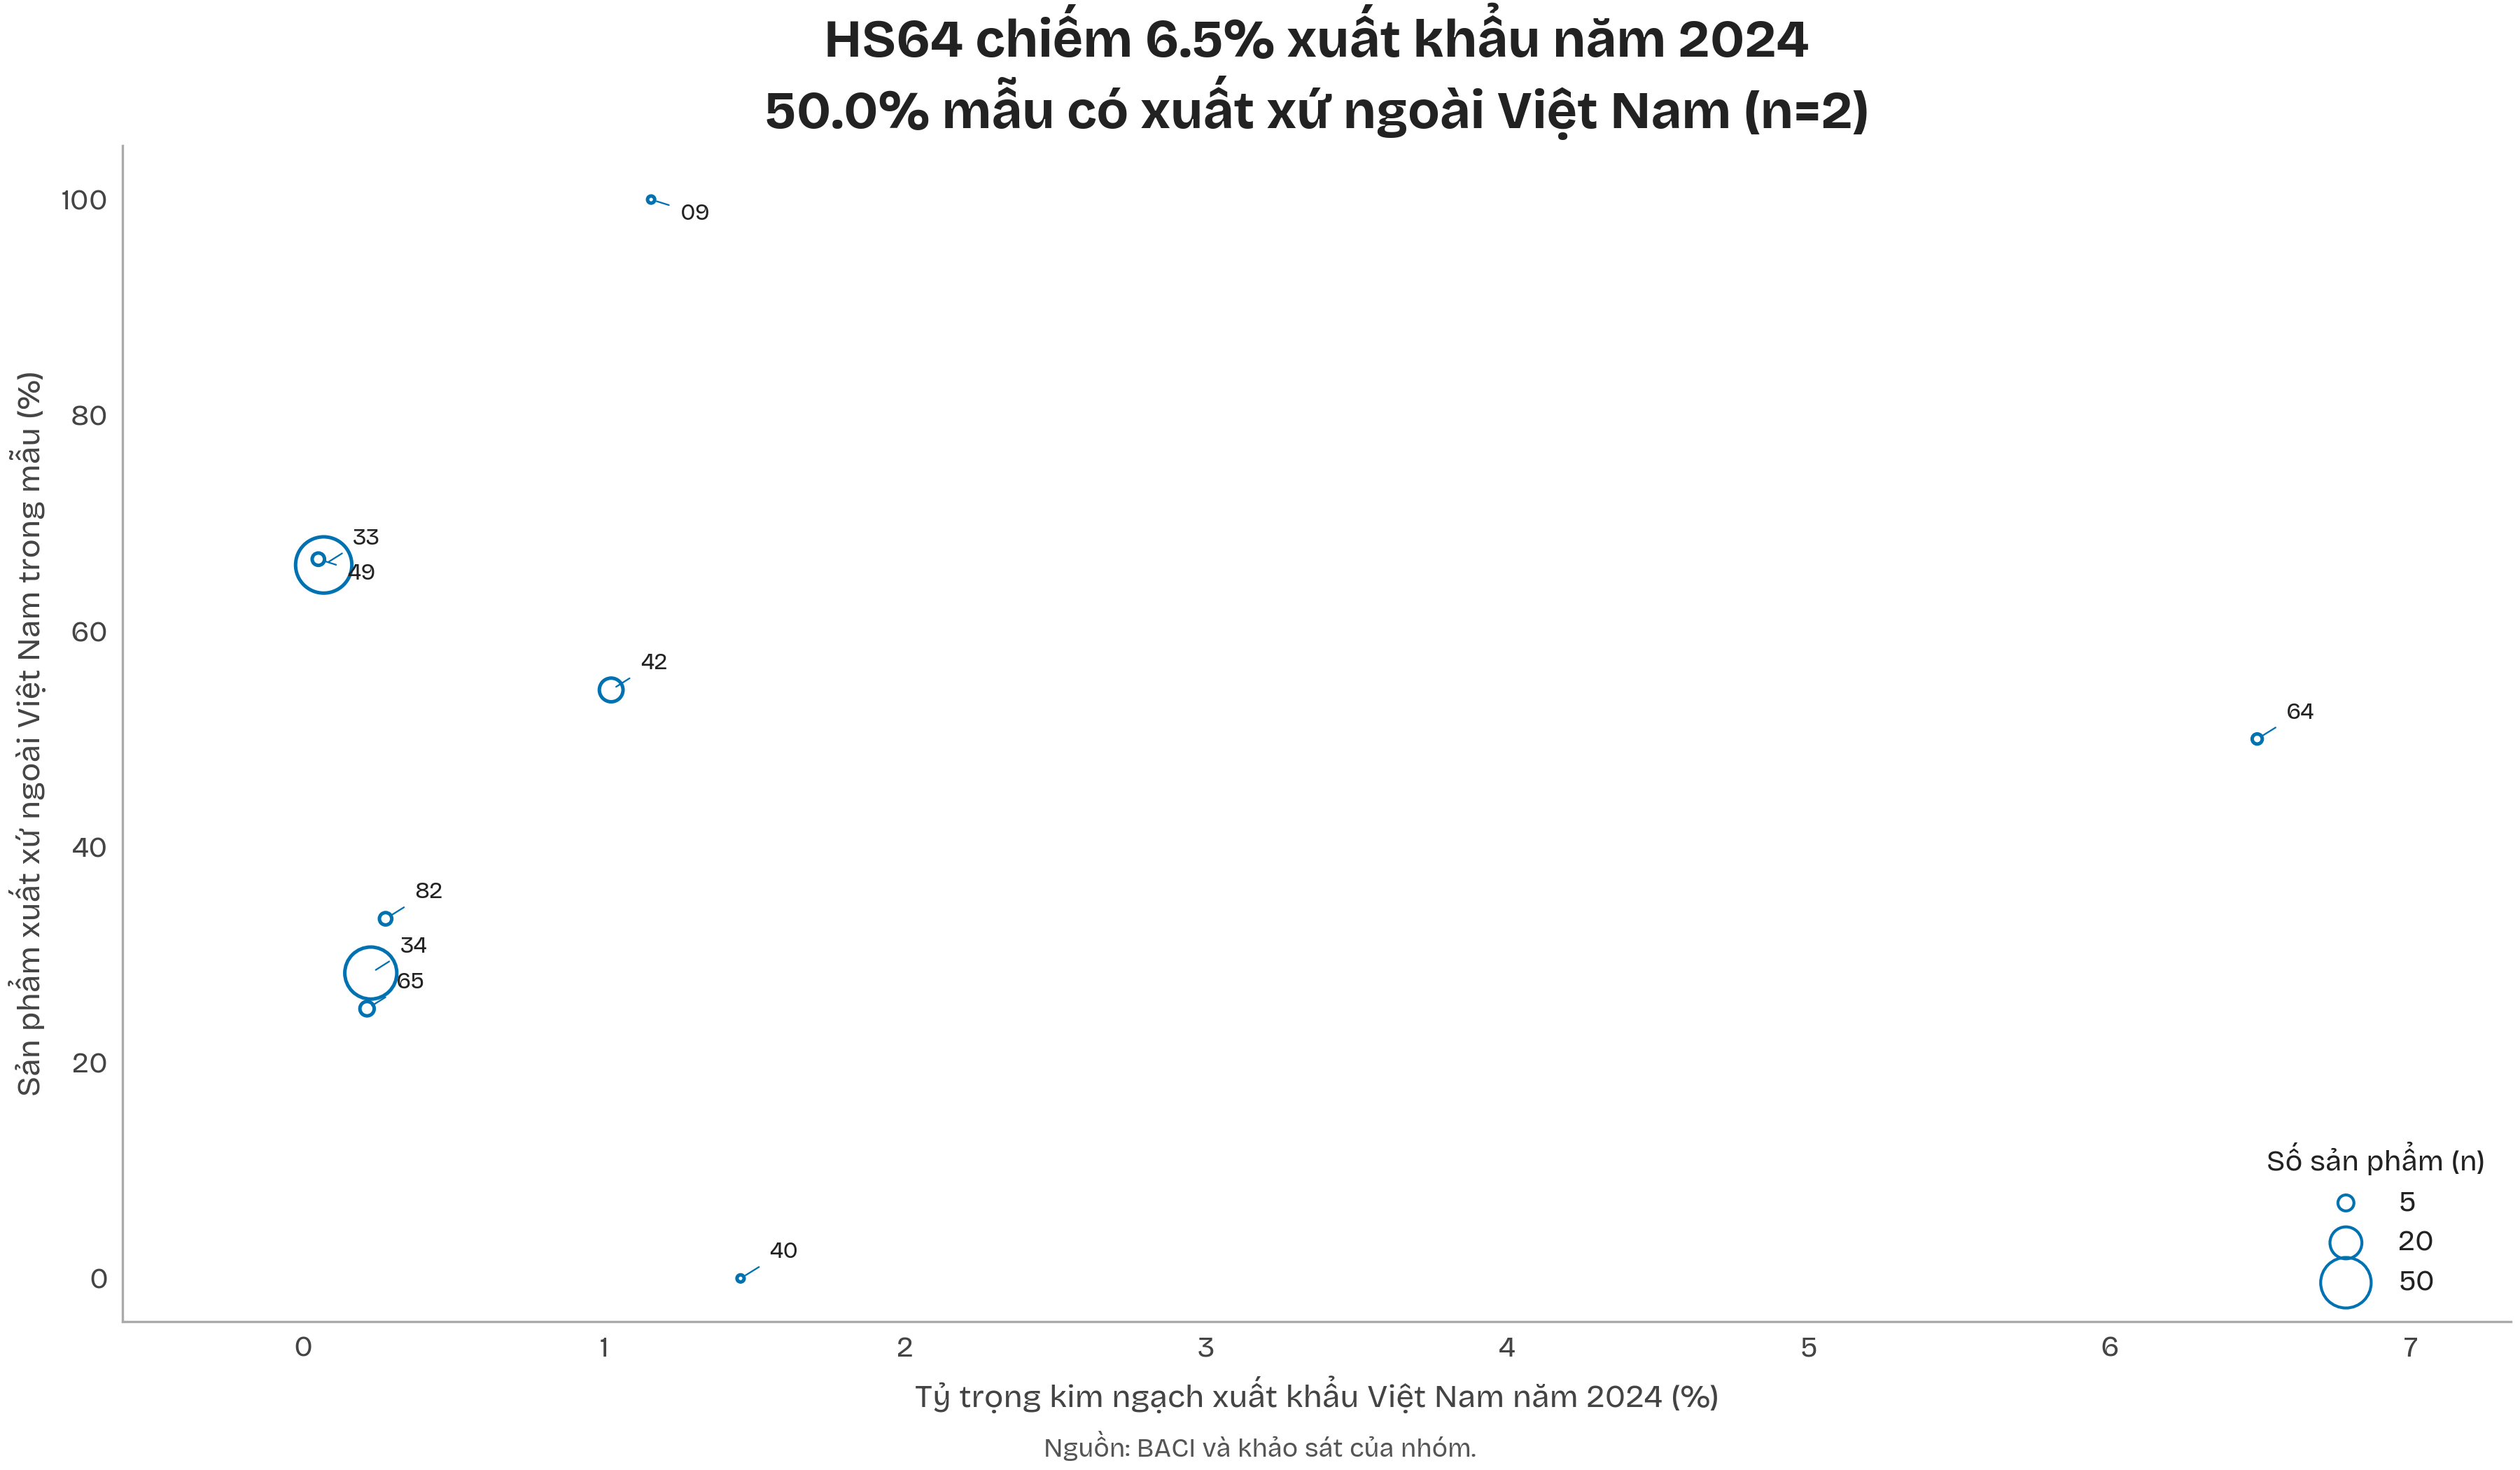

In [3]:
from pathlib import Path
import sys

year_c07a = 2024
min_n_c07a = 1
color_c07a = None  # None dùng màu nhấn mặc định của T10.
bubble_scale_c07a = 6
compatible_hs2_c07a = {"09", "33", "34", "40", "42", "49", "64", "65", "82"}  # Đối chiếu UNSD tại Cell 1.

root_c07a = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data/clean/baci_hs_summary.csv").is_file()),
    Path.cwd(),
)
style_dir_c07a = str(root_c07a / "notebooks")
if style_dir_c07a not in sys.path:
    sys.path.insert(0, style_dir_c07a)
from house_style import house_style as hs

df_c07a = lay_du_lieu_c07a(root_c07a / "data/clean/baci_hs_summary.csv",
                           root_c07a / "data/clean/survey_final.csv", year_c07a,
                           min_n_c07a, compatible_hs2_c07a)
assert df_c07a["hs2"].is_unique
assert df_c07a["outside_vn_pct"].between(0, 100).all()
assert df_c07a["export_share_pct"].between(0, 100).all()
assert df_c07a["export_share_pct"].sum() <= 100 + 1e-8
print(df_c07a.to_string(index=False, float_format=lambda x: f"{x:.1f}"))
with hs.apply_style():
    fig_c07a, ax_c07a = ve_c07a(df_c07a, year_c07a, color_c07a or hs.ACCENT_COLOR, bubble_scale_c07a,
                               provisional=compatible_hs2_c07a is None)
    output_c07a = root_c07a / f"outputs/core_charts/C07/C07A_{year_c07a}.png"
    output_c07a.parent.mkdir(parents=True, exist_ok=True)
    fig_c07a.savefig(output_c07a, dpi=hs.THEME["savefig.dpi"])
    plt.show()


### Kết luận · C07A

**Action title** - Trong 9 chương được giữ, HS64 chiếm **6.5%** kim ngạch xuất khẩu Việt Nam năm 2024, còn **50.0%** mẫu HS64 có xuất xứ ngoài Việt Nam (**1/2 sản phẩm**).

HS64 có cỡ mẫu nhỏ. Ở HS33, chương có nhiều sản phẩm khảo sát nhất trong hình, **41/62 sản phẩm (66.1%)** có xuất xứ ngoài Việt Nam và chương chiếm khoảng **0.1%** tổng xuất khẩu Việt Nam. Kết quả mô tả mẫu tại các cửa hàng khảo sát.

Phạm vi hiển thị gồm **9 chương và 140 sản phẩm** sau khi loại các dòng cần xác minh xuất xứ và các chương có liên kết chéo HS2002–HS2022 theo tiêu chí ở Cell 1.
